# anchorline tutorial: how each step works

This notebook walks through what `anchorline` computes. Each step has its formula, the call that runs it, and a
check that **recomputes the step by hand** from the outputs. The formulas are therefore verified against the code,
not just described.

**Notation**

| symbol | meaning |
|---|---|
| $x_{g,s}$ | expression of gene $g$ in sample $s$ (any scale) |
| $r_{g,s}$ | within-sample rank of gene $g$ in sample $s$, scaled to 0–1 |
| $p(s)$ | platform of sample $s$ (RNA-seq, microarray, sci-Plex pseudobulk) |
| $U$, $D$ | up and down genes of a signature |
| $c$ | a cell line; $j$ a study; $i$ a drug-vs-control comparison ("contrast") |

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import anchorline as al

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20); pd.set_option("display.max_colwidth", 60)
al.settings.figdir = "figures"          # save=True writes here
al.settings.set_figure_params(fontsize=8.5, dpi=150)
atlas = al.load()                       # first time: downloads the atlas (~560 MB) to al.settings.data_dir
atlas

loading atlas from /Users/sina.kanannejad/.anchorline/data (~1-2 min, ~1.5 GB RAM)
  8894 reference samples (2805 untreated), 42003 genes; 1608 drug-vs-control contrasts


anchorline Atlas (/Users/sina.kanannejad/.anchorline/data)
  reference: 8894 samples (2805 untreated) x 42003 genes
  contrasts: 1608 (226 studies, 63 models, 363 drugs)

## Step 0: one scale for every platform

The atlas mixes RNA-seq, microarrays and single-cell pseudobulk, so expression values are not comparable.
Every sample is therefore stored as **within-sample ranks**:

$$r_{g,s} = \frac{\operatorname{rank}(x_{g,s}) - 1}{n_s - 1} \in [0, 1]$$

where $n_s$ is the number of measured genes in the sample. A value of 0.9 means "in the top 10 % of genes in this
sample", on any platform.

Each rank is then **centred on the gene's platform mean**, which removes probe and platform effects:

$$\tilde r_{g,s} = r_{g,s} - \bar r_{g,\,p(s)}$$

The reference holds 2,805 untreated samples (DMSO, vehicle or no treatment). Below is HOXA9 in a few lines.

In [2]:
ctl = atlas.controls
g = atlas.gi["HOXA9"]
R = pd.DataFrame({"cell_line": ctl.cell_line.values, "platform": ctl.platform.values,
                  "rank_HOXA9": atlas.R[atlas.ctrl, g].astype(float),
                  "centred_HOXA9": atlas.Rc[:, g]})
R[R.cell_line.isin(["MOLM-13", "MV4-11", "NOMO-1", "Kasumi-1", "K562", "HL-60"])].groupby("cell_line")[
    ["rank_HOXA9", "centred_HOXA9"]].median().sort_values("rank_HOXA9", ascending=False).round(3)

,rank_HOXA9,centred_HOXA9
cell_line,,
MOLM-13,0.922,0.177
NOMO-1,0.918,0.199
MV4-11,0.893,0.151
Kasumi-1,0.480,-0.259
HL-60,0.346,-0.397
K562,0.161,-0.512


## Step 1: the differentiation axis (Zeng 2022 hierarchy)

Zeng et al. 2022 (*Nat Med* 28:1212–1223, doi:10.1038/s41591-022-01819-x) defined AML cell-type signatures from
single-cell data. For each state $k$ the **state score** is the mean rank of its genes $G_k$:

$$S_{k,s} = \frac{1}{|G_k|}\sum_{g \in G_k} r_{g,s}$$

Scores are z-scored over the reference ($z_{k,s}$) and turned into weights with a softmax. **Pseudotime** is the
weighted position on the axis:

$$w_{k,s} = \frac{e^{z_{k,s}}}{\sum_{k'} e^{z_{k',s}}}, \qquad
\tau_s = \sum_k w_{k,s}\,\mathrm{pos}_k$$

with $\mathrm{pos}$ = quiescent LSPC 0, primed LSPC 1, cycling LSPC 1.5, GMP 2, ProMono 3, Mono 4.

The 2-D **state map** uses two differences:

$$\text{GMP}\rightarrow\text{myeloid} = \tfrac12(S_\text{ProMono} + S_\text{Mono}) - S_\text{GMP}, \qquad
\text{GMP}\rightarrow\text{primitive} = \tfrac12(S_\text{Quiescent} + S_\text{Primed}) - S_\text{GMP}$$

In [3]:
import numpy as np
from anchorline._core import STATES, state_scores, add_pseudotime
s0 = atlas.ctrl[np.isfinite(atlas.controls.pseudotime.values)][:5]   # 5 untreated samples (52 have no score)
S = add_pseudotime(state_scores(atlas.R[s0], atlas.genes, atlas.sets), atlas.mu, atlas.sd)
check = pd.DataFrame({"recomputed": S.pseudotime.values, "stored": atlas.obs.pseudotime.values[s0]})
print("pseudotime recomputed == stored:", np.allclose(check.recomputed, check.stored, atol=1e-3))
S_all = add_pseudotime(state_scores(atlas.R, atlas.genes, atlas.sets), atlas.mu, atlas.sd)
print("... and for all", len(S_all), "reference samples:",
      np.allclose(S_all.pseudotime.values, atlas.obs.pseudotime.values, atol=1e-3, equal_nan=True))
check.round(3)

pseudotime recomputed == stored: True
... and for all 8894 reference samples: True


,recomputed,stored
0,2.335,2.335
1,2.318,2.318
2,2.333,2.333
3,1.876,1.876
4,1.807,1.807


## Step 2a: matching a signature

For every untreated sample $s$, the match score is the mean centred rank of the up genes minus that of the down genes:

$$m_s = \frac{1}{|U|}\sum_{g\in U}\tilde r_{g,s} \;-\; \frac{1}{|D|}\sum_{g\in D}\tilde r_{g,s}$$

Genes missing from the reference are skipped.

In [4]:
sig = al.sig.get("Umeda2024_KMT2Ar_high")
mt = al.tl.match(atlas, sig)
ui = [atlas.gi[x] for x in mt.up]; di = [atlas.gi[x] for x in mt.down]
m_hand = np.nanmean(atlas.Rc[:, ui], 1) - np.nanmean(atlas.Rc[:, di], 1)   # all untreated samples (NaN = gene not measured)
m_hand = pd.Series(m_hand, index=atlas.controls.index).loc[mt.samples.index]
print("signature score by hand == package:", np.allclose(m_hand.values, mt.samples.score.values, atol=1e-5, equal_nan=True))

signature score by hand == package: True


## Step 2b: matching a patient sample

A whole profile is compared without letting platform or tumour-vs-cell-line differences dominate.

1. Rank the query within itself: $r_g^{q}$.
2. **Centre it on its own cohort** $B$ (the other samples in your table or AnnData), so that only what is specific to
   this patient remains:
   $$q_g = r^{q}_g - \frac{1}{|B|}\sum_{b\in B} r_{g,b}$$
   Without a background, the atlas mean is used instead.
3. Keep the $H$ = 2,000 genes that vary most across the reference.
4. The score is the Spearman correlation on those genes:
   $$m_s = \rho_{\text{Spearman}}\big(q_H,\; \tilde r_{H,s}\big)$$

The query also gets its own pseudotime $\tau_q$ (the star in the plots) and a **patient-specific signature**: the
100 genes most above and the 100 most below its cohort. This signature is used for the reversal term below.

In [5]:
adata = al.datasets.beataml_demo()          # 45 BeatAML samples (downloads the demo data the first time)
pid = adata.obs_names[adata.obs.group == "KMT2A-r"][0]
mt_p = al.tl.match(atlas, adata, sample=pid)
print(mt_p.query, "| pseudotime of the patient:", round(float(mt_p.query_state.pseudotime), 2))
print("patient-specific up genes:", mt_p.up[:12])
mt_p.table.head(5)[["score", "studies", "genotype"]]

Query('BA2031R', sample: 22843 genes, background: 45 samples) | pseudotime of the patient: 2.82
patient-specific up genes: ['KLRC2', 'LAMP5', 'UNC5C', 'IFI27', 'SAGE1', 'TNIP3', 'CT45A5', 'HS3ST4', 'CLSTN2', 'AR', 'TGM5', 'ZFP57']


,score,studies,genotype
cell_line,,,
MOLM-14,0.137107,9,KMT2A-r
MOLM-13,0.113563,44,KMT2A-r
MV4-11,0.110476,52,KMT2A-r
OCI-AML3,0.080936,29,NPM1c
EOL-1,0.079834,1,other


## Step 3: from samples to a cell-line score

Scores are averaged within each study, then across studies:

$$M_c = \frac{1}{J_c}\sum_{j=1}^{J_c}\;\frac{1}{|s\in(c,j)|}\sum_{s\in(c,j)} m_s$$

Taking the **mean** over studies, not the best study, avoids favouring lines profiled in many studies. MOLM-13 has
44 studies, so its best study would be high by chance alone.

The selected lines get a **match weight**, used to rank drugs:

$$w_c = \operatorname{clip}\!\left(\frac{M_c - \operatorname{median}_{c'} M_{c'}}{\max_{c\in\text{sel}} M_c - \operatorname{median}_{c'} M_{c'}},\;0.05,\;1\right)$$

In [6]:
t = mt.samples.groupby(["cell_line", "accession"]).score.mean().groupby("cell_line").mean().sort_values(ascending=False)
print("cell-line score by hand == package:", np.allclose(t.values, mt.table.score.values))
sel = mt.select(5); med = mt.table.score.median()
w_hand = ((mt.table.score[sel] - med) / (mt.table.score[sel].max() - med)).clip(0.05, 1)
pd.DataFrame({"score": mt.table.score[sel], "weight_by_hand": w_hand.round(3), "weight_package": mt.weights(5)})

cell-line score by hand == package: True


,score,weight_by_hand,weight_package
cell_line,,,
OCI-AML2,0.129570,1.000,1.000
NOMO-1,0.112956,0.881,0.881
MOLM-13,0.106263,0.833,0.833
MOLM-14,0.087806,0.700,0.700
IMS-M2,0.036047,0.328,0.328


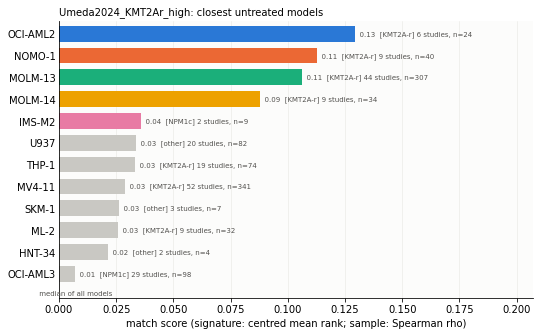

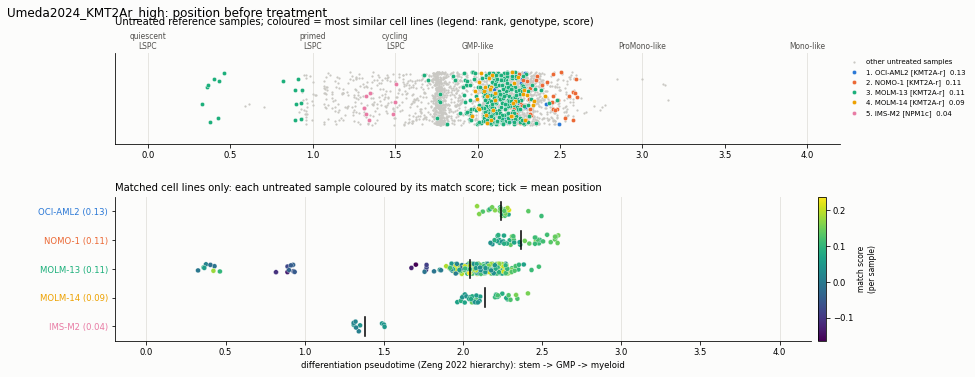

In [7]:
al.pl.match_ranking(mt, n_top=12)
al.pl.pseudotime(mt, n_top=5)

## Step 4: three terms per drug comparison

For each comparison $i$ (one drug, dose and time in one cell line, against matched controls), the atlas stores
$\mathrm{LFC}_{g,i}$ = mean log2 expression of the treated samples − that of the controls. Counts are log2(CPM+1).

| term | formula | meaning |
|---|---|---|
| magnitude | $A_i = \sqrt{\tfrac{1}{\lvert PC\rvert}\sum_{g\in PC}\mathrm{LFC}_{g,i}^2}$ | overall change of the ~19,300 protein-coding genes |
| reversal | $e_i = \overline{\mathrm{LFC}}_{U,i} - \overline{\mathrm{LFC}}_{D,i}$, scored as $-e_i$ | does the drug push the query signature down? |
| differentiation | $\Delta\tau_i = \tau(\text{treated}) - \tau(\text{control})$ | > 0: toward myeloid |

Each term becomes a **robust z-score**. Magnitude is scaled within each data type, because arrays give smaller
fold changes than RNA-seq:

$$z(x) = \frac{x - \operatorname{median}(x)}{1.4826\,\operatorname{MAD}(x)}$$

Each z-score is clipped to ±3 so that no single term dominates. Their mean is the comparison's **composite**:

$$C_i = \tfrac13\big[\operatorname{clip}(z(A_i)) + \operatorname{clip}(z(-e_i)) + \operatorname{clip}(z(\Delta\tau_i))\big]$$

In [8]:
dr = al.tl.rank_drugs(atlas, mt, cell_lines=5)
T = dr.contrasts
C_hand = T[["magnitude_z", "reversal_z", "diff_shift_z"]].clip(-3, 3).mean(1)
print("composite by hand == package:", np.allclose(C_hand, T.composite))
T[["drug_key", "cell_line", "dose", "time", "magnitude", "magnitude_z", "signature_change", "reversal_z",
   "diff_shift", "diff_shift_z", "composite"]].head(8).round(3)

composite by hand == package: True


,drug_key,cell_line,dose,time,magnitude,magnitude_z,signature_change,reversal_z,diff_shift,diff_shift_z,composite
contrast,,,,,,,,,,,
GSE94849__735|pinometostat+pinometostat||10d;10d|nomo1|,pinometostat,NOMO-1,,10d;10d,1.930,3.000,-1.331,3.000,0.344,3.000,3.000
GSE228307__433|ziftomenib|||molm13|,ziftomenib,MOLM-13,,,1.116,1.788,-2.098,3.000,0.429,3.000,2.596
GSE173574__gsm|pinometostat|1um;100nm|5d|molm13|,pinometostat,MOLM-13,1um;100nm,5d,0.814,1.673,-1.292,3.000,0.396,3.000,2.558
GSE281506__546|selumetinib||6d|nomo1|,selumetinib,NOMO-1,,6d,0.744,1.377,-0.720,2.744,0.230,2.962,2.361
GSE173574__gsm|pinometostat|100nm|5d|molm13|,pinometostat,MOLM-13,100nm,5d,0.649,0.977,-1.068,3.000,0.356,3.000,2.326
GSE149049__gsm|MI-3454+gilteritinib|||molm13|,gilteritinib + MI-3454,MOLM-13,,,0.629,0.894,-0.825,3.000,0.448,3.000,2.298
GSE156182__295|GSK2830371+nutlin-3a|5mm;20mm;5mm;20mm|5d;16h;16h|nomo1|,GSK2830371 + nutlin-3a,NOMO-1,5mm;20mm;5mm;20mm,5d;16h;16h,1.444,2.603,-0.495,1.785,0.144,1.741,2.043
GSE225153__gsm|carbocyclic 5-aza-dC|0.5um;0.5um||molm13|,carbocyclic 5-aza-dC,MOLM-13,0.5um;0.5um,,1.336,2.462,-0.588,2.182,0.110,1.269,1.971


## Step 5: from comparisons to a drug score

Each comparison is weighted by its cell line's match weight and by its replicate support, with
$n_r = \min(n_\text{treated}, n_\text{control})$:

$$\omega_i = w_{c(i)}\cdot\frac{n_r}{n_r+1}$$

Per drug $d$, with $n_d$ comparisons:

$$C_d = \frac{\sum_{i\in d}\omega_i C_i}{\sum_{i\in d}\omega_i}, \qquad
\text{score}_d = C_d\cdot\frac{n_d}{n_d+1}$$

The factor $n_d/(n_d+1)$ shrinks thinly supported drugs: ×0.5 for one comparison, ×0.75 for three, ×0.9 for nine.
**Consistency** is the fraction of comparisons with $C_i > 0$.

**Tiers:**
- **T1:** at least 2 studies and consistency ≥ 75 %.
- **T2:** at least 2 comparisons.
- **T3:** a single comparison. Treat these as leads.

In [9]:
d = "pinometostat"
g_ = T[T.drug_key == d]
C_d = np.average(g_.composite, weights=g_.weight)
score_hand = C_d * len(g_) / (len(g_) + 1)
print(f"{d}: {len(g_)} comparisons, C_d = {C_d:.3f}, score by hand = {score_hand:.3f}, package = {dr.drugs.score[d]:.3f}")
dr.drugs.head(10)[["drug_name", "tier", "score", "composite", "magnitude_z", "reversal_z", "diff_shift",
                   "consistency", "n_contrasts", "n_studies"]].round(3)

pinometostat: 11 comparisons, C_d = 1.170, score by hand = 1.073, package = 1.073


,drug_name,tier,score,composite,magnitude_z,reversal_z,diff_shift,consistency,n_contrasts,n_studies
drug_key,,,,,,,,,,
ziftomenib,ziftomenib,T3,1.298,2.596,1.788,3.000,0.429,1.000,1,1
gilteritinib + MI-3454,gilteritinib + MI-3454,T3,1.149,2.298,0.894,3.000,0.448,1.000,1,1
pinometostat,pinometostat,T1,1.073,1.170,0.461,1.450,0.174,1.000,11,5
carbocyclic 5-aza-dC,carbocyclic 5-aza-dC,T3,0.985,1.971,2.462,2.182,0.110,1.000,1,1
MI-3454,MI-3454,T3,0.975,1.951,0.000,3.000,0.222,1.000,1,1
selumetinib,selumetinib,T2,0.884,1.179,0.987,1.642,0.085,0.667,3,1
GSK2830371 + nutlin-3a,GSK2830371 + nutlin-3a,T2,0.831,1.108,1.435,1.454,0.052,1.000,3,1
SGC0946,SGC0946,T3,0.723,1.447,0.774,1.449,0.170,1.000,1,1
azacitidine + venetoclax,azacitidine + venetoclax,T3,0.714,1.428,1.843,-0.559,0.236,1.000,1,1


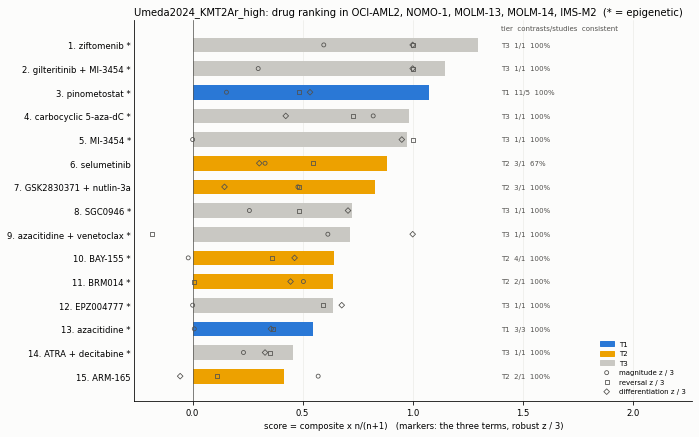

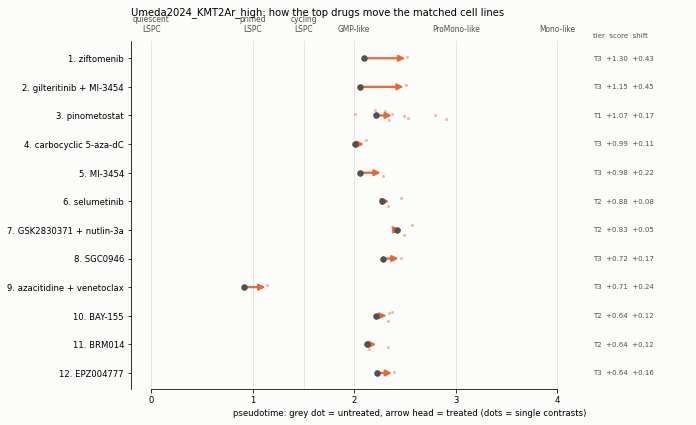

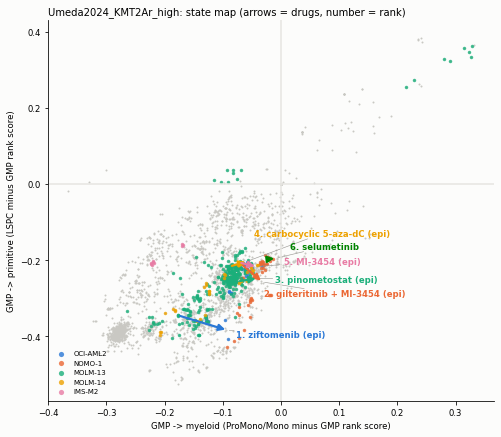

In [10]:
al.pl.drug_ranking(dr, n_top=15)
al.pl.drug_shifts(dr, n_top=12)
al.pl.state_map(dr, n_top=6)

## Step 6: drug classes

Comparisons are grouped by drug class; a combination counts in each of its classes. Per class, the plots show:
- the median $\Delta\tau$ with its interquartile range;
- the share of comparisons with $\Delta\tau > 0$ (toward myeloid);
- the median change on the GMP→myeloid and GMP→primitive axes (the shift map).

In [11]:
dr.classes.head(8)[["drug_class", "n_contrasts", "n_drugs", "n_studies", "diff_shift", "diff_shift_q25",
                    "diff_shift_q75", "frac_toward_myeloid", "top_drugs"]].round(3)

,drug_class,n_contrasts,n_drugs,n_studies,diff_shift,diff_shift_q25,diff_shift_q75,frac_toward_myeloid,top_drugs
0,VEGFR/FGFR/RTK (other),1,1,1,0.189,0.189,0.189,1.000,TP-0903
1,DOT1L,14,4,7,0.167,0.066,0.286,0.857,"SGC0946, EPZ004777, pinometostat"
2,menin-KMT2A,10,7,5,0.122,0.073,0.215,1.000,"ziftomenib, gilteritinib + MI-3454, MI-3454"
3,topoisomerase,2,2,1,0.089,0.083,0.095,1.000,"cytarabine + daunorubicin, daunorubicin"
4,DHODH (pyrimidine synthesis),4,1,1,0.070,0.051,0.114,1.000,Brequinar
5,FLT3,12,6,7,0.055,0.030,0.088,0.833,"gilteritinib + MI-3454, gilteritinib, midostaurin"
6,nucleotide synthesis / antimetabolite,4,2,2,0.051,0.000,0.101,0.750,"cytarabine + daunorubicin, cytarabine"
7,retinoid / differentiation,9,5,5,0.028,-0.026,0.063,0.667,"ATRA + decitabine, ATRA, arsenic trioxide + ATRA"


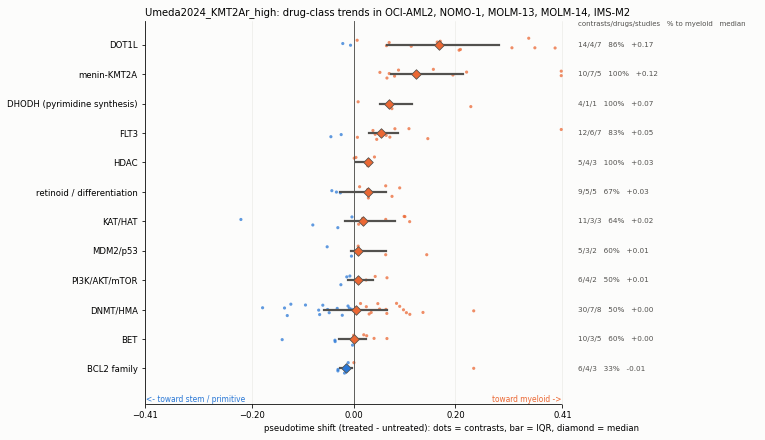

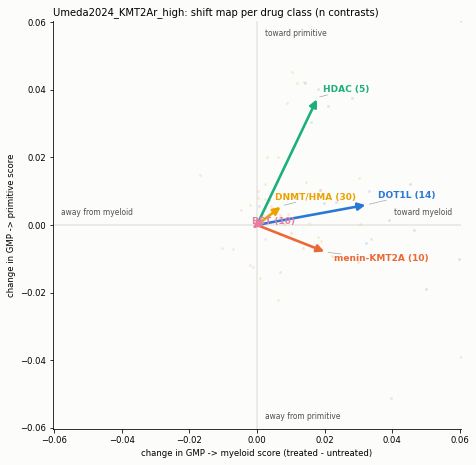

In [12]:
al.pl.class_trends(dr, n_top=12)
al.pl.class_shift_map(dr, classes=["menin-KMT2A", "DOT1L", "BET", "DNMT/HMA", "HDAC"])

## Step 7: gene-level read-outs (reported, not scored)

**Expressed genes.** A gene counts as expressed in comparison $i$ if its mean within-sample rank is at least 0.5 in
the control samples or in the treated samples. Genes that are not expressed in either arm count as no change (0),
so noisy near-zero genes don't count.

$$E_{g,i} = \big[\max(\bar r_{g,\text{ctrl}},\ \bar r_{g,\text{treated}}) \ge 0.5\big]$$

**Change indices**, computed for the SURFY surfaceome (2,886 proteins; Bausch-Fluck et al. 2018 *PNAS*
115:E10988, doi:10.1073/pnas.1808790115) and for all protein-coding genes:

$$\text{net index}_i = \frac{\#\{g: E_{g,i},\ \mathrm{LFC}_{g,i} > 1\} - \#\{g: E_{g,i},\ \mathrm{LFC}_{g,i} < -1\}}{\#\{g: E_{g,i}\}} \in [-1, 1],
\qquad
\text{intensity}_i = \frac{\sum_g E_{g,i}\,|\mathrm{LFC}_{g,i}|}{\#\{g: E_{g,i}\}}$$

Per drug, gene values are $\omega$-weighted means. A gene is listed as a drug's top change only if
$|\overline{\mathrm{LFC}}| > 1$ **and** it changes in at least half of that drug's comparisons.

net index by hand: 0.2373 | package: 0.2373


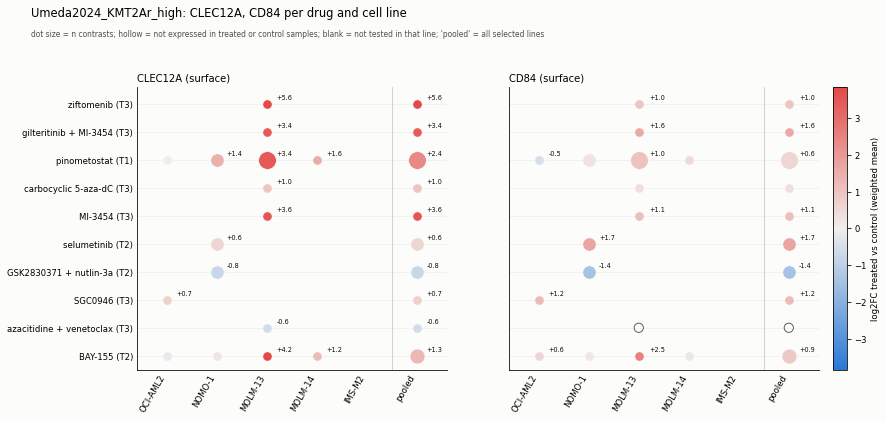

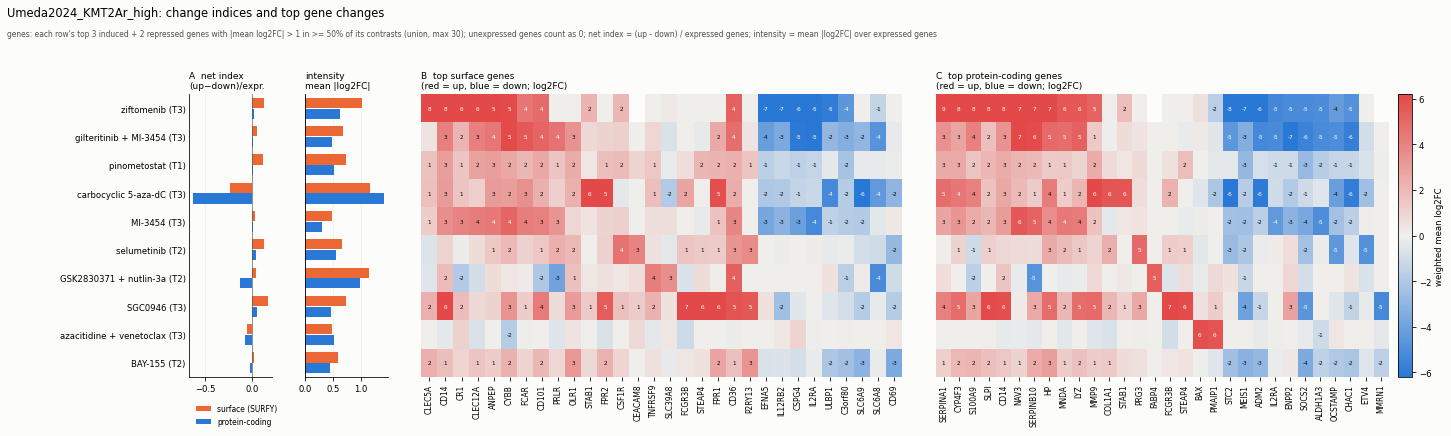

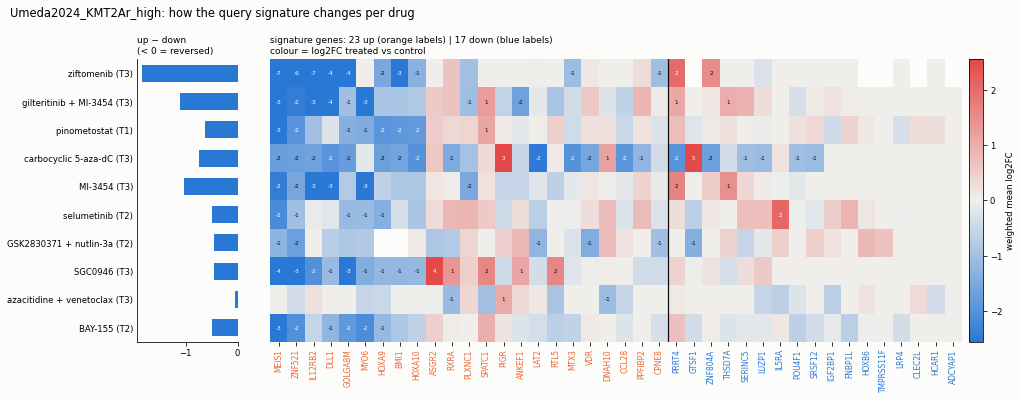

In [13]:
i = T.index[0]
print("net index by hand:", round((T.n_surface_up[i] - T.n_surface_down[i]) / T.n_expressed_surface[i], 4),
      "| package:", round(T.surface_net_index[i], 4))
al.pl.gene_changes(dr, genes=["CLEC12A", "CD84"], n_top=10)
al.pl.top_gene_changes(dr, n_top=10)
al.pl.signature_changes(dr, n_top=10)

## Summary of the workflow

```python
atlas = al.load()                                   # downloads the atlas the first time
mt = al.tl.match(atlas, query)                      # Steps 0-3
dr = al.tl.rank_drugs(atlas, mt, cell_lines=5)      # Steps 4-5
dr.classes                                          # Step 6
al.tl.gene_changes(dr, genes); al.tl.change_indices(dr)   # Step 7
```

**Caveats**
- A match means "most similar available model", not the same disease. If a group has no matching line, it lands on generic lines, and a low top score with a flat ranking is the warning sign.
- Match scores are relative: compare them across lines within one query, not across queries.
- T3 drugs rest on a single comparison.

Continue with `01_builtin_signatures`, `02_custom_signature` and `03_sample_csv_and_anndata`.